# Experiment 02: Topology Perturbations

This notebook compares controlled perturbations of a synthetic disk. The goal is to see how Dice and BCE relate to changes in connected components and holes.

In [1]:
import sys
from pathlib import Path

# Add the source directory to sys.path for module imports
project_root = Path.cwd().parent
source_dir = project_root / 'src'
if source_dir.exists() and str(source_dir) not in sys.path:
    sys.path.append(str(source_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from topological_segmentation.data.perturbations import (
    add_component,
    add_hole,
    erode_boundary,
    split_object,
)
from topological_segmentation.data.synthetic_2d import make_disk
from topological_segmentation.losses.segmentation import (
    binary_cross_entropy,
    dice_score,
)
from topological_segmentation.topology.betti import compute_betti_numbers
from topological_segmentation.topology.persistence import get_persistence_diagram
from topological_segmentation.topology.pce import (
    finite_birth_persistence,
    pce_from_diagrams,
)

## 1. Generate controlled predictions

The ground truth is a filled disk. Each prediction applies one controlled change: boundary erosion, an interior hole, a split, or a disconnected extra component.

In [2]:
gt = make_disk(size=64, radius=20)

preds = {
    'perfect': gt,
    'boundary': erode_boundary(gt, amount=2),
    'hole': add_hole(gt, radius=6),
    'split': split_object(gt, width=2),
    'extra_component': add_component(gt, radius=8, center=(10, 10)),
}

## 2. Compare segmentation and topology metrics

In [3]:
rows = []
for name, pred in preds.items():
    beta_0, beta_1 = compute_betti_numbers(pred)
    rows.append({
        'name': name,
        'dice': float(dice_score(pred, gt)),
        'bce': float(binary_cross_entropy(pred.astype(float), gt.astype(float))),
        'beta_0': beta_0,
        'beta_1': beta_1,
    })

df = pd.DataFrame(rows)
display(df.style.format({'dice': '{:.4f}', 'bce': '{:.4f}'}))

,name,dice,bce,beta_0,beta_1
0,perfect,1.0000,0.0000,1,0
1,boundary,0.9041,0.9894,1,0
2,hole,0.9529,0.5082,1,1
3,split,0.9671,0.3598,2,0
4,extra_component,0.9273,0.8860,2,0


## 2.1 Compare prediction topology with PCE

PCE is computed in one direction: each prediction diagram is used to explain the ground-truth diagram. The reported values are therefore `prediction -> ground truth`.

In [75]:
def diagram_for(mask, homology_dimension):
    entries = get_persistence_diagram(mask.astype(float), homology_dimension)
    return finite_birth_persistence(entries)


def directional_report(reference, candidate):
    report = pce_from_diagrams(reference, candidate, tau=1.0)
    return {
        'pce': report.pce,
        'excess': report.entropy_excess,
        'unexplained': report.unexplained_mass,
        'status': report.status,
    }


gt_diagrams = {
    dimension: diagram_for(gt, dimension)
    for dimension in (0, 1)
}

pce_rows = []
for name, pred in preds.items():
    row = {'name': name}
    for dimension in (0, 1):
        pred_diagram = diagram_for(pred, dimension)
        #gt_to_pred = directional_report(gt_diagrams[dimension], pred_diagram)
        pred_to_gt = directional_report(pred_diagram, gt_diagrams[dimension])
        #row[f'pce_h{dimension}_gt_to_pred'] = gt_to_pred['pce']
        #row[f'excess_h{dimension}_gt_to_pred'] = gt_to_pred['excess']
        #row[f'unexplained_h{dimension}_gt_to_pred'] = gt_to_pred['unexplained']
        row[f'pce_h{dimension}_pred_to_gt'] = pred_to_gt['pce']
        row[f'excess_h{dimension}_pred_to_gt'] = pred_to_gt['excess']
        row[f'unexplained_h{dimension}_pred_to_gt'] = pred_to_gt['unexplained']
        row[f'h{dimension}_diagram_size'] = len(pred_diagram)
    row['pce_excess_pred_to_gt_total'] = np.nansum([
        row['excess_h0_pred_to_gt'],
        row['excess_h1_pred_to_gt'],
    ])
    row['unexplained_pred_to_gt_total'] = np.nansum([
        row['unexplained_h0_pred_to_gt'],
        row['unexplained_h1_pred_to_gt'],
    ])
    pce_rows.append(row)

pce_df = pd.DataFrame(pce_rows)
display(pce_df.style.format(precision=4, na_rep='undefined'))

,name,pce_h0_pred_to_gt,excess_h0_pred_to_gt,unexplained_h0_pred_to_gt,h0_diagram_size,pce_h1_pred_to_gt,excess_h1_pred_to_gt,unexplained_h1_pred_to_gt,h1_diagram_size,pce_excess_pred_to_gt_total,unexplained_pred_to_gt_total
0,perfect,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0,0.0000,0.0000
1,boundary,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0,0.0000,0.0000
2,hole,0.0000,0.0000,0.0000,0,0.1250,0.1250,0.1175,1,0.1250,0.1175
3,split,0.1250,0.1250,0.1175,1,0.0000,0.0000,0.0000,0,0.1250,0.1175
4,extra_component,0.1250,0.1250,0.1175,1,0.0000,0.0000,0.0000,0,0.1250,0.1175


## 2.2 Combined comparison

,name,dice,bce,beta_0,beta_1,pce_excess_pred_to_gt_total,unexplained_pred_to_gt_total,h0_diagram_size,h1_diagram_size
0,perfect,1.0000,0.0000,1,0,0.0000,0.0000,0,0
1,boundary,0.9041,0.9894,1,0,0.0000,0.0000,0,0
2,hole,0.9529,0.5082,1,1,0.1250,0.1175,0,1
3,split,0.9671,0.3598,2,0,0.1250,0.1175,1,0
4,extra_component,0.9273,0.8860,2,0,0.1250,0.1175,1,0


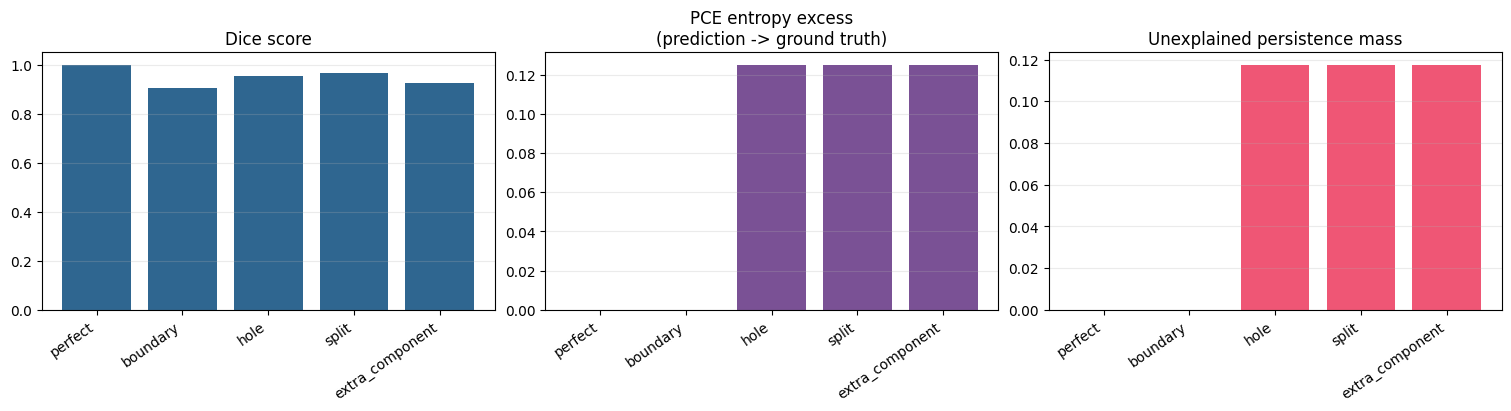

In [62]:
comparison_df = df.merge(pce_df, on='name')
display(comparison_df[[
    'name',
    'dice',
    'bce',
    'beta_0',
    'beta_1',
    'pce_excess_pred_to_gt_total',
    'unexplained_pred_to_gt_total',
    'h0_diagram_size',
    'h1_diagram_size',
]].style.format({
    'dice': '{:.4f}',
    'bce': '{:.4f}',
    'pce_excess_pred_to_gt_total': '{:.4f}',
    'unexplained_pred_to_gt_total': '{:.4f}',
}, na_rep='undefined'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
labels = comparison_df['name']
x = np.arange(len(comparison_df))

axes[0].bar(x, comparison_df['dice'], color='#2f6690')
axes[0].set_title('Dice score')
axes[0].set_ylim(0, 1.05)

axes[1].bar(x, comparison_df['pce_excess_pred_to_gt_total'], color='#7a5195')
axes[1].set_title('PCE entropy excess\n(prediction -> ground truth)')

axes[2].bar(x, comparison_df['unexplained_pred_to_gt_total'], color='#ef5675')
axes[2].set_title('Unexplained persistence mass')

for ax in axes:
    ax.set_xticks(x, labels, rotation=35, ha='right')
    ax.grid(axis='y', alpha=0.25)

plt.show()

## 2.3 PCE metric differences by prediction

The entropy excess measures the additional topology discrepancy introduced by using each prediction instead of the reference diagram. The table separates connected-component differences (`H0`) from hole differences (`H1`).

In [63]:
pce_difference_df = comparison_df[[
    'name',
    'excess_h0_pred_to_gt',
    'excess_h1_pred_to_gt',
    'pce_excess_pred_to_gt_total',
    'unexplained_h0_pred_to_gt',
    'unexplained_h1_pred_to_gt',
    'unexplained_pred_to_gt_total',
]].rename(columns={
    'excess_h0_pred_to_gt': 'pce_difference_h0',
    'excess_h1_pred_to_gt': 'pce_difference_h1',
    'pce_excess_pred_to_gt_total': 'pce_difference_total',
    'unexplained_h0_pred_to_gt': 'unexplained_mass_h0',
    'unexplained_h1_pred_to_gt': 'unexplained_mass_h1',
    'unexplained_pred_to_gt_total': 'unexplained_mass_total',
})

display(pce_difference_df.style.format({
    'pce_difference_h0': '{:.4f}',
    'pce_difference_h1': '{:.4f}',
    'pce_difference_total': '{:.4f}',
    'unexplained_mass_h0': '{:.4f}',
    'unexplained_mass_h1': '{:.4f}',
    'unexplained_mass_total': '{:.4f}',
}, na_rep='undefined'))

,name,pce_difference_h0,pce_difference_h1,pce_difference_total,unexplained_mass_h0,unexplained_mass_h1,unexplained_mass_total
0,perfect,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,boundary,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,hole,0.0000,0.1250,0.1250,0.0000,0.1175,0.1175
3,split,0.1250,0.0000,0.1250,0.1175,0.0000,0.1175
4,extra_component,0.1250,0.0000,0.1250,0.1175,0.0000,0.1175


## 3. Visualize persistence diagrams

Each column shows one binary mask. The top row contains finite `H0` features, which represent additional connected components. The bottom row contains finite `H1` features, which represent holes. Points use birth-persistence coordinates; the y-axis is feature lifetime.

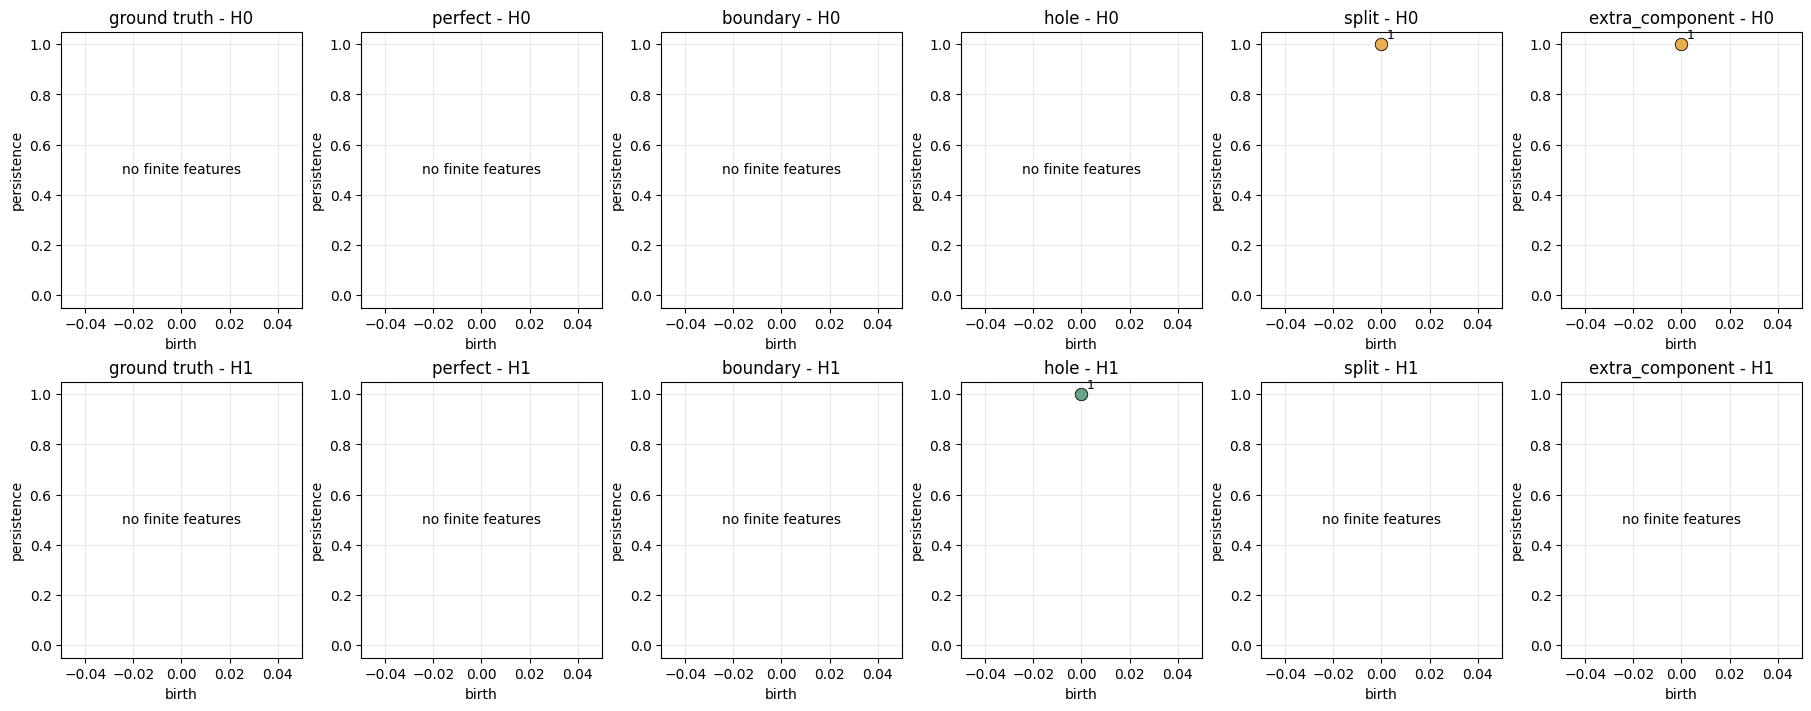

In [66]:
all_diagrams = {'ground truth': gt_diagrams}
for name, pred in preds.items():
    all_diagrams[name] = {
        dimension: diagram_for(pred, dimension)
        for dimension in (0, 1)
    }

max_birth = max(
    [diagram[:, 0].max() for diagrams in all_diagrams.values() for diagram in diagrams.values() if len(diagram)]
    or [1.0]
)
max_lifetime = max(
    [diagram[:, 1].max() for diagrams in all_diagrams.values() for diagram in diagrams.values() if len(diagram)]
    or [1.0]
)

fig, axes = plt.subplots(2, len(all_diagrams), figsize=(18, 7), constrained_layout=True)
colors = {0: '#edae49', 1: '#66a182'}

for column, (name, diagrams) in enumerate(all_diagrams.items()):
    for row, dimension in enumerate((0, 1)):
        ax = axes[row, column]
        diagram = diagrams[dimension]
        if len(diagram):
            ax.scatter(
                diagram[:, 0],
                diagram[:, 1],
                s=80,
                color=colors[dimension],
                edgecolor='black',
                linewidth=0.6,
            )
            for point_index, (birth, lifetime) in enumerate(diagram, start=1):
                ax.annotate(
                    str(point_index),
                    (birth, lifetime),
                    xytext=(4, 4),
                    textcoords='offset points',
                    fontsize=9,
                )
        else:
            ax.text(0.5, 0.5, 'no finite features', ha='center', va='center', transform=ax.transAxes)
        ax.set_xlim(-0.05, max_birth + 0.05)
        ax.set_ylim(-0.05, max_lifetime + 0.05)
        ax.grid(alpha=0.25)
        ax.set_title(f'{name} - H{dimension}')
        ax.set_xlabel('birth')
        ax.set_ylabel('persistence')

plt.show()

## 3. Visualize the masks

The masks make the topology changes visible: the hole changes `beta_1`, while the split and extra-component cases change `beta_0`.

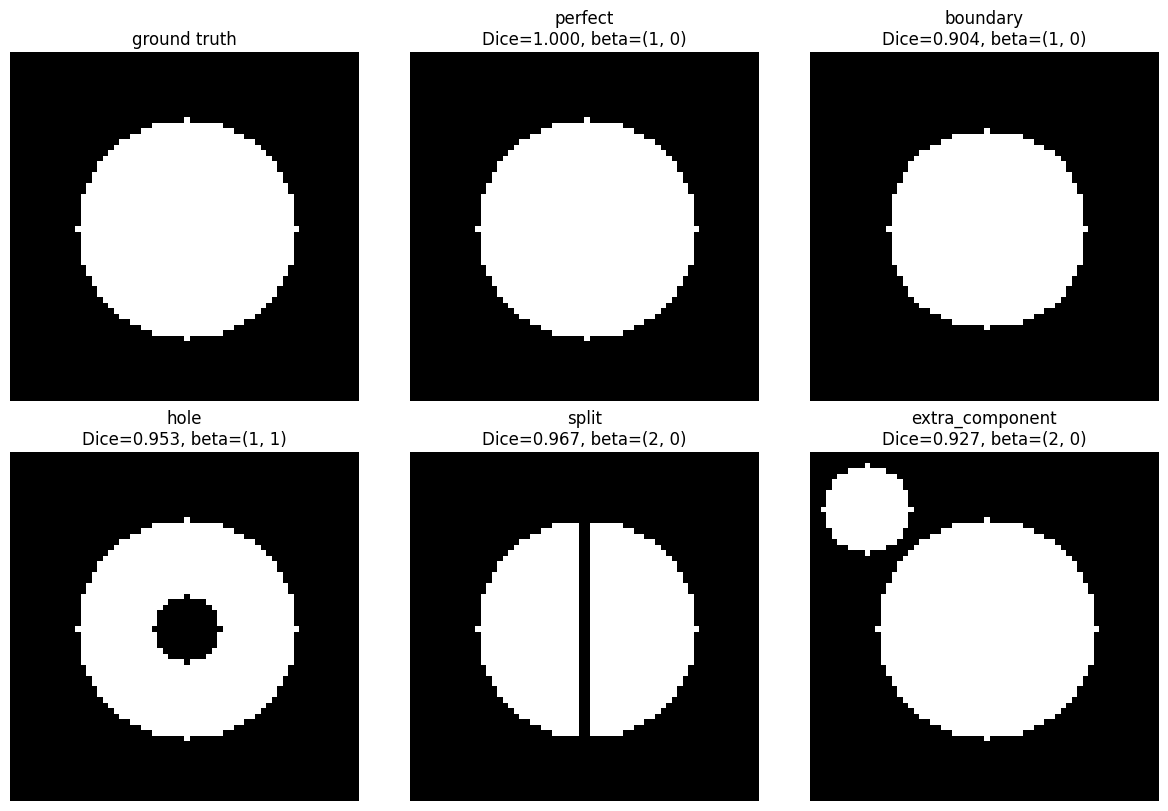

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
axes = axes.ravel()

axes[0].imshow(gt, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('ground truth')
axes[0].axis('off')

for ax, (name, mask) in zip(axes[1:], preds.items()):
    ax.imshow(mask, cmap='gray', vmin=0, vmax=1)
    row = df.loc[df['name'] == name].iloc[0]
    ax.set_title(f"{name}\nDice={row['dice']:.3f}, beta=({int(row['beta_0'])}, {int(row['beta_1'])})")
    ax.axis('off')

plt.show()

## 4. Plot metric differences

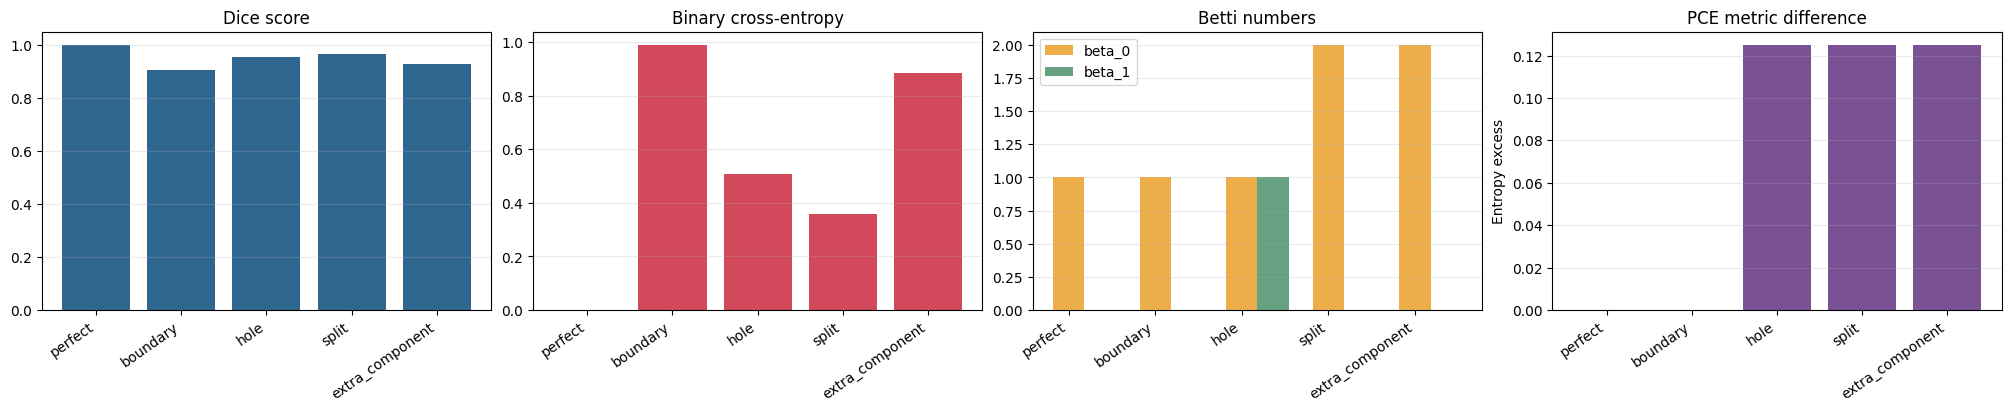

In [68]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), constrained_layout=True)
labels = comparison_df['name']
x = np.arange(len(comparison_df))

axes[0].bar(x, comparison_df['dice'], color='#2f6690')
axes[0].set_title('Dice score')
axes[0].set_ylim(0, 1.05)

axes[1].bar(x, comparison_df['bce'], color='#d1495b')
axes[1].set_title('Binary cross-entropy')

axes[2].bar(x, comparison_df['beta_0'], width=0.36, label='beta_0', color='#edae49')
axes[2].bar(x + 0.36, comparison_df['beta_1'], width=0.36, label='beta_1', color='#66a182')
axes[2].set_title('Betti numbers')
axes[2].legend()

axes[3].bar(x, comparison_df['pce_excess_pred_to_gt_total'], color='#7a5195')
axes[3].set_title('PCE metric difference')
axes[3].set_ylabel('Entropy excess')

for ax in axes:
    ax.set_xticks(x, labels, rotation=35, ha='right')
    ax.grid(axis='y', alpha=0.25)

plt.show()

## Interpretation

- Boundary erosion changes the overlap metrics while preserving the disk topology.
- The hole perturbation creates one foreground hole, increasing `beta_1` from 0 to 1.
- The split and extra-component perturbations create two connected foreground components, increasing `beta_0` from 1 to 2.
- These examples show why Dice and BCE should be considered together with topology-aware summaries when structural correctness matters.